# ComPlaintAI-Bank — BERT Fine-Tuning on BANKING77

**Goal:** Fine-tune `bert-base-uncased` to classify BANKING77's 77 intent classes. This saved model will later be used by the ComPlaintAI-Bank application in VS Code.

## Before running
1. Select **Runtime → Change runtime type → T4 GPU** (or another available GPU), then save.
2. Run this notebook from top to bottom.
3. Authorize Google Drive when prompted.
4. Keep the runtime connected until training, evaluation, and the final save finish.

The notebook downloads the official `PolyAI/banking77` dataset from Hugging Face; no CSV upload is required. It creates a stratified validation split from the official training set and keeps the official test set separate until final evaluation.

## Saved artifacts
- Best validation-macro-F1 model and tokenizer
- Label mapping for all 77 intents
- Accuracy, macro/weighted precision, recall and F1, balanced accuracy, top-3 accuracy, Matthews correlation, Cohen's kappa, log loss, test runtime and throughput
- Per-intent report, confusion matrices, test predictions, training history, diagnostic plots, configuration metadata, and a ZIP copy of the model

**Important:** intent classification is a triage aid, not proof that a complaint allegation is true. The later app's priority assignment remains rule-based. Do not use real customer information or secrets in this notebook.

## 1. Install compatible libraries

These libraries are installed in the Colab runtime only, not on your laptop.

In [1]:
%pip install -q "transformers==4.46.3" "datasets==3.2.0" "accelerate==1.2.1" "huggingface_hub<1.0" scikit-learn pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 72.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.4/336.4 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 82.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
diffuse

## 2. Connect Google Drive

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os, json, time, random, zipfile, inspect
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, EarlyStoppingCallback, set_seed,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
    top_k_accuracy_score, log_loss, classification_report, confusion_matrix,
)

SEED = 42
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
NUM_EPOCHS = 4
LEARNING_RATE = 2e-5
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
VALIDATION_SIZE = 0.10

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

DRIVE_ROOT = Path("/content/drive/MyDrive/ComPlaintAI-Bank")
MODEL_DIR = DRIVE_ROOT / "models" / "bert_banking77_model"
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = DRIVE_ROOT / "training_runs" / f"bert_banking77_{TIMESTAMP}"
WORK_DIR = Path("/content/bert_banking77_work")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", os.sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU is assigned; CPU training may take much longer.")
print("Model destination:", MODEL_DIR)
print("Run reports destination:", RUN_DIR)

Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Model destination: /content/drive/MyDrive/ComPlaintAI-Bank/models/bert_banking77_model
Run reports destination: /content/drive/MyDrive/ComPlaintAI-Bank/training_runs/bert_banking77_20261017_123648


## 3. Download and inspect BANKING77

The dataset metadata supplies the numeric-label-to-intent mapping. The notebook stops if that mapping is missing or does not contain all 77 labels rather than guessing.

In [4]:
dataset_dict = load_dataset("PolyAI/banking77")
if "train" not in dataset_dict or "test" not in dataset_dict:
    raise ValueError(f"Expected train and test splits, found: {list(dataset_dict.keys())}")

label_feature = dataset_dict["train"].features["label"]
if not hasattr(label_feature, "names") or not label_feature.names:
    raise ValueError("Dataset label names are missing; stop rather than guessing the label mapping.")

label_names = list(label_feature.names)
num_labels = len(label_names)
if num_labels != 77:
    raise ValueError(f"Expected 77 intent labels, found {num_labels}.")

train_df = dataset_dict["train"].to_pandas()[["text", "label"]].copy()
test_df = dataset_dict["test"].to_pandas()[["text", "label"]].copy()

for split_name, frame in [("train", train_df), ("test", test_df)]:
    if frame["text"].isna().any() or frame["label"].isna().any():
        raise ValueError(f"Missing text/label values in {split_name} split.")
    frame["text"] = frame["text"].astype(str).str.strip()
    frame["label"] = frame["label"].astype(int)
    if (frame["text"] == "").any():
        raise ValueError(f"Empty text in {split_name} split.")
    if not frame["label"].between(0, num_labels - 1).all():
        raise ValueError(f"Invalid label IDs in {split_name} split.")

id_to_label = {int(i): str(name) for i, name in enumerate(label_names)}
label_to_id = {str(name): int(i) for i, name in enumerate(label_names)}

print("Training examples:", len(train_df))
print("Official test examples:", len(test_df))
print("Intent classes:", num_labels)
print("Unique train labels:", train_df["label"].nunique())
print("Unique test labels:", test_df["label"].nunique())
display(train_df.head())
display(pd.DataFrame({"label_id": range(num_labels), "intent": label_names}).head(15))

if train_df["label"].nunique() != num_labels or test_df["label"].nunique() != num_labels:
    raise ValueError("At least one intent is absent from a split; check the dataset version.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

banking77.py: 0.00B [00:00, ?B/s]

dataset_infos.json: 0.00B [00:00, ?B/s]

The repository for PolyAI/banking77 contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/PolyAI/banking77.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


...

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

Training examples: 10003
Official test examples: 3080
Intent classes: 77
Unique train labels: 77
Unique test labels: 77


,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11
3,Can I track my card while it is in the process...,11
4,"How do I know if I will get my card, or if it ...",11


,label_id,intent
0,0,activate_my_card
1,1,age_limit
2,2,apple_pay_or_google_pay
3,3,atm_support
4,4,automatic_top_up
5,5,balance_not_updated_after_bank_transfer
6,6,balance_not_updated_after_cheque_or_cash_deposit
7,7,beneficiary_not_allowed
8,8,cancel_transfer
9,9,card_about_to_expire


## 4. Make a stratified validation split

Ten percent of the official training split becomes validation data. The official test split is not used for training or selecting a checkpoint.

In [5]:
train_part_df, val_df = train_test_split(
    train_df, test_size=VALIDATION_SIZE, random_state=SEED,
    stratify=train_df["label"]
)
train_part_df = train_part_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_counts = train_part_df["label"].value_counts().reindex(range(num_labels), fill_value=0)
val_counts = val_df["label"].value_counts().reindex(range(num_labels), fill_value=0)
test_counts = test_df["label"].value_counts().reindex(range(num_labels), fill_value=0)
split_summary = pd.DataFrame({
    "label_id": range(num_labels), "intent": label_names,
    "train_count": train_counts.values, "validation_count": val_counts.values,
    "test_count": test_counts.values
})
split_summary.to_csv(RUN_DIR / "dataset_split_summary.csv", index=False)
print(f"Train: {len(train_part_df):,} | Validation: {len(val_df):,} | Official test: {len(test_df):,}")
display(split_summary.head(10))

Train: 9,002 | Validation: 1,001 | Official test: 3,080


,label_id,intent,train_count,validation_count,test_count
0,0,activate_my_card,143,16,40
1,1,age_limit,99,11,40
2,2,apple_pay_or_google_pay,113,13,40
3,3,atm_support,78,9,40
4,4,automatic_top_up,114,13,40
5,5,balance_not_updated_after_bank_transfer,154,17,40
6,6,balance_not_updated_after_cheque_or_cash_deposit,163,18,40
7,7,beneficiary_not_allowed,140,16,40
8,8,cancel_transfer,141,16,40
9,9,card_about_to_expire,116,13,40


## 5. Tokenize and build datasets

Maximum sequence length is 128 tokens, a practical starting point for BANKING77's short utterances. Dynamic padding reduces unnecessary computation within each batch.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

def as_dataset(frame):
    return Dataset.from_pandas(frame[["text", "label"]].copy(), preserve_index=False)

train_raw = as_dataset(train_part_df)
val_raw = as_dataset(val_df)
test_raw = as_dataset(test_df)

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

train_tokenized = train_raw.map(tokenize_batch, batched=True, remove_columns=["text"])
val_tokenized = val_raw.map(tokenize_batch, batched=True, remove_columns=["text"])
test_tokenized = test_raw.map(tokenize_batch, batched=True, remove_columns=["text"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Tokenization complete.")
print("Tokenized fields:", list(train_tokenized[0].keys()))
print("First example token count:", len(train_tokenized[0]["input_ids"]))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/9002 [00:00<?, ? examples/s]

Map:   0%|          | 0/1001 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

Tokenization complete.
Tokenized fields: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
First example token count: 12


## 6. Load BERT and define evaluation metrics

The best checkpoint is selected using validation **macro-F1**, so each intent contributes equally to model selection.

In [7]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=num_labels, id2label=id_to_label, label2id=label_to_id
)

def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    y_true = np.asarray(eval_pred.label_ids, dtype=int)
    y_pred = np.argmax(logits, axis=-1)
    probs = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).cpu().numpy()
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_precision": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "weighted_recall": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "top3_accuracy": float(top_k_accuracy_score(y_true, probs, k=3, labels=np.arange(num_labels))),
    }

print("Base model:", MODEL_NAME)
print("Output labels:", model.config.num_labels)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Base model: bert-base-uncased
Output labels: 77
Trainable parameters: 109,541,453


## 7. Configure training

Uses learning rate `2e-5`, weight decay, warmup, per-epoch validation, best-checkpoint selection and early stopping. Mixed precision is enabled only when CUDA is available.

In [8]:
args_kwargs = dict(
    output_dir=str(WORK_DIR / "checkpoints"),
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=1,
    weight_decay=0.01,
    warmup_ratio=0.10,
    logging_strategy="steps",
    logging_steps=100,
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=2,
    logging_first_step=True,
)
params = inspect.signature(TrainingArguments.__init__).parameters
args_kwargs["eval_strategy" if "eval_strategy" in params else "evaluation_strategy"] = "epoch"
training_args = TrainingArguments(**args_kwargs)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("Validation cadence: each epoch")
print("Early-stopping patience: 2 evaluation rounds")
print("FP16 enabled:", torch.cuda.is_available())

Validation cadence: each epoch
Early-stopping patience: 2 evaluation rounds
FP16 enabled: True


/tmp/ipykernel_1707/4123130002.py:28: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


## 8. Fine-tune BERT

Keep the runtime connected until the save and verification cells finish. Training checkpoints are written to the temporary Colab runtime; the selected model and reports are copied to Drive later.

In [9]:
train_start = time.time()
train_result = trainer.train()
training_wall_time_seconds = time.time() - train_start
train_metrics = dict(train_result.metrics)
train_metrics["training_wall_time_seconds"] = float(training_wall_time_seconds)

print("Training completed in seconds:", round(training_wall_time_seconds, 2))
print("Best validation macro-F1:", trainer.state.best_metric)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
display(pd.DataFrame([train_metrics]).T.rename(columns={0: "value"}))

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Top3 Accuracy
1,2.909100,2.258540,0.672328,0.712134,0.643260,0.621636,0.732563,0.672328,0.645441,0.883117
2,1.203500,1.023774,0.855145,0.845988,0.832510,0.827793,0.859371,0.855145,0.846225,0.949051
3,0.731200,0.668498,0.890110,0.903256,0.876936,0.879820,0.899801,0.890110,0.888332,0.966034
4,0.527100,0.584694,0.900100,0.912626,0.886932,0.889711,0.909592,0.900100,0.898359,0.968032


Training completed in seconds: 326.29
Best validation macro-F1: 0.8897106569076488
Best checkpoint: /content/bert_banking77_work/checkpoints/checkpoint-2252


,value
train_runtime,3.258468e+02
train_samples_per_second,1.105060e+02
train_steps_per_second,6.911000e+00
total_flos,7.285257e+14
train_loss,1.658785e+00
epoch,4.000000e+00
training_wall_time_seconds,3.262947e+02


## 9. Evaluate the selected model on the official test set

Final evaluation is performed after best-checkpoint selection. The official test set remains separate from training and validation.

In [10]:
test_output = trainer.predict(test_tokenized, metric_key_prefix="test")
test_logits = test_output.predictions
if isinstance(test_logits, tuple):
    test_logits = test_logits[0]
y_true = np.asarray(test_output.label_ids, dtype=int)
y_pred = np.argmax(test_logits, axis=-1)
probabilities = torch.softmax(torch.tensor(test_logits, dtype=torch.float32), dim=-1).cpu().numpy()

test_metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    "weighted_precision": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
    "weighted_recall": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
    "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "top3_accuracy": float(top_k_accuracy_score(y_true, probabilities, k=3, labels=np.arange(num_labels))),
    "matthews_correlation_coefficient": float(matthews_corrcoef(y_true, y_pred)),
    "cohen_kappa": float(cohen_kappa_score(y_true, y_pred)),
    "multiclass_log_loss": float(log_loss(y_true, probabilities, labels=np.arange(num_labels))),
}
for key, value in test_output.metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        test_metrics[key.replace("test_", "")] = float(value)

print("OFFICIAL TEST METRICS")
for key, value in test_metrics.items():
    print(f"{key:34s}: {value:.6f}" if isinstance(value, float) else f"{key:34s}: {value}")

OFFICIAL TEST METRICS
accuracy                          : 0.906169
macro_precision                   : 0.912554
macro_recall                      : 0.906169
macro_f1                          : 0.905917
weighted_precision                : 0.912554
weighted_recall                   : 0.906169
weighted_f1                       : 0.905917
balanced_accuracy                 : 0.906169
top3_accuracy                     : 0.971104
matthews_correlation_coefficient  : 0.905020
cohen_kappa                       : 0.904934
multiclass_log_loss               : 0.607842
loss                              : 0.607842
runtime                           : 4.650700
samples_per_second                : 662.265000
steps_per_second                  : 20.857000


## 10. Save comprehensive metrics and predictions

The per-intent report provides precision, recall, F1 and support for each class. Top-class confidence is a softmax score, not the probability that a customer's allegation is true.

In [11]:
report = classification_report(
    y_true, y_pred, labels=list(range(num_labels)), target_names=label_names,
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(RUN_DIR / "classification_report.csv", index=True, index_label="intent_or_average")

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_labels)))
cm_df = pd.DataFrame(cm, index=label_names, columns=label_names)
cm_df.index.name = "true_intent"
cm_df.to_csv(RUN_DIR / "confusion_matrix_counts.csv")

row_sums = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
cm_norm_df = pd.DataFrame(cm_norm, index=label_names, columns=label_names)
cm_norm_df.index.name = "true_intent"
cm_norm_df.to_csv(RUN_DIR / "confusion_matrix_normalized.csv")

top3_ids = np.argsort(probabilities, axis=1)[:, -3:][:, ::-1]
predictions_df = pd.DataFrame({
    "text": test_df["text"].tolist(),
    "true_label_id": y_true,
    "true_intent": [id_to_label[int(i)] for i in y_true],
    "predicted_label_id": y_pred,
    "predicted_intent": [id_to_label[int(i)] for i in y_pred],
    "predicted_confidence": probabilities.max(axis=1),
    "top3_intents": [" | ".join(id_to_label[int(i)] for i in row) for row in top3_ids],
    "correct": y_true == y_pred,
})
predictions_df.to_csv(RUN_DIR / "test_predictions.csv", index=False)

history_df = pd.DataFrame(trainer.state.log_history)
history_df.to_csv(RUN_DIR / "training_history.csv", index=False)
pd.DataFrame([test_metrics]).to_csv(RUN_DIR / "test_metrics_summary.csv", index=False)

print("Detailed reports saved to:", RUN_DIR)
print("Per-intent report rows:", len(report_df), "| Confusion matrix:", cm.shape)
display(report_df.loc[[x for x in label_names[:10] if x in report_df.index]])

Detailed reports saved to: /content/drive/MyDrive/ComPlaintAI-Bank/training_runs/bert_banking77_20261017_123648
Per-intent report rows: 80 | Confusion matrix: (77, 77)


,precision,recall,f1-score,support
activate_my_card,1.000000,0.900,0.947368,40.0
age_limit,1.000000,1.000,1.000000,40.0
apple_pay_or_google_pay,0.975610,1.000,0.987654,40.0
atm_support,0.975000,0.975,0.975000,40.0
automatic_top_up,1.000000,0.925,0.961039,40.0
balance_not_updated_after_bank_transfer,0.756098,0.775,0.765432,40.0
balance_not_updated_after_cheque_or_cash_deposit,1.000000,0.950,0.974359,40.0
beneficiary_not_allowed,0.972973,0.900,0.935065,40.0
cancel_transfer,1.000000,0.950,0.974359,40.0
card_about_to_expire,1.000000,1.000,1.000000,40.0


## 11. Save training curves, confusion matrix and per-intent F1 plot

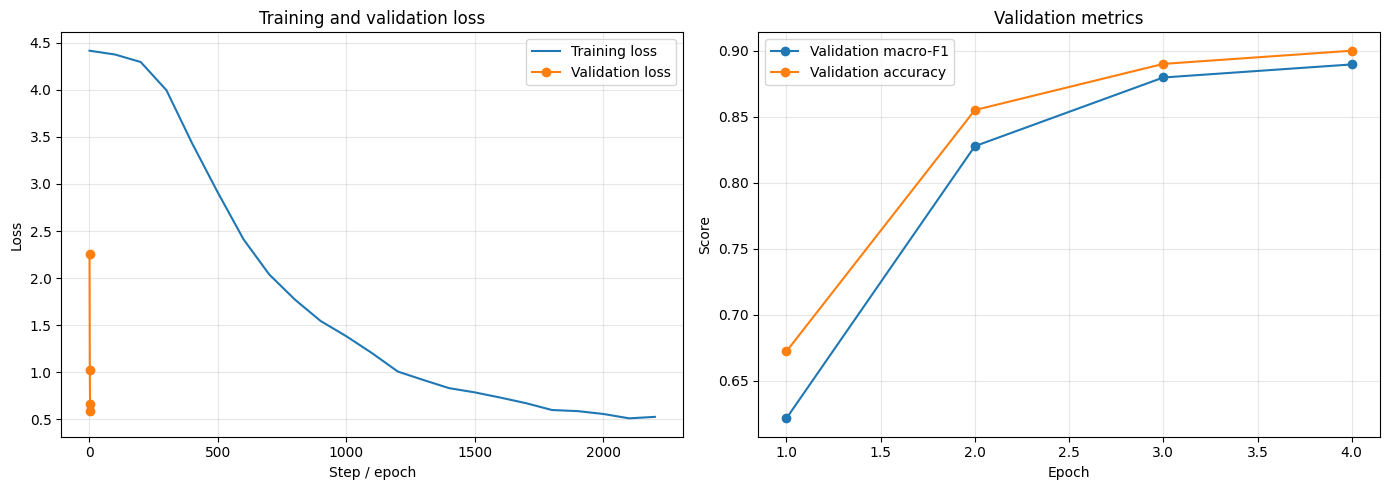

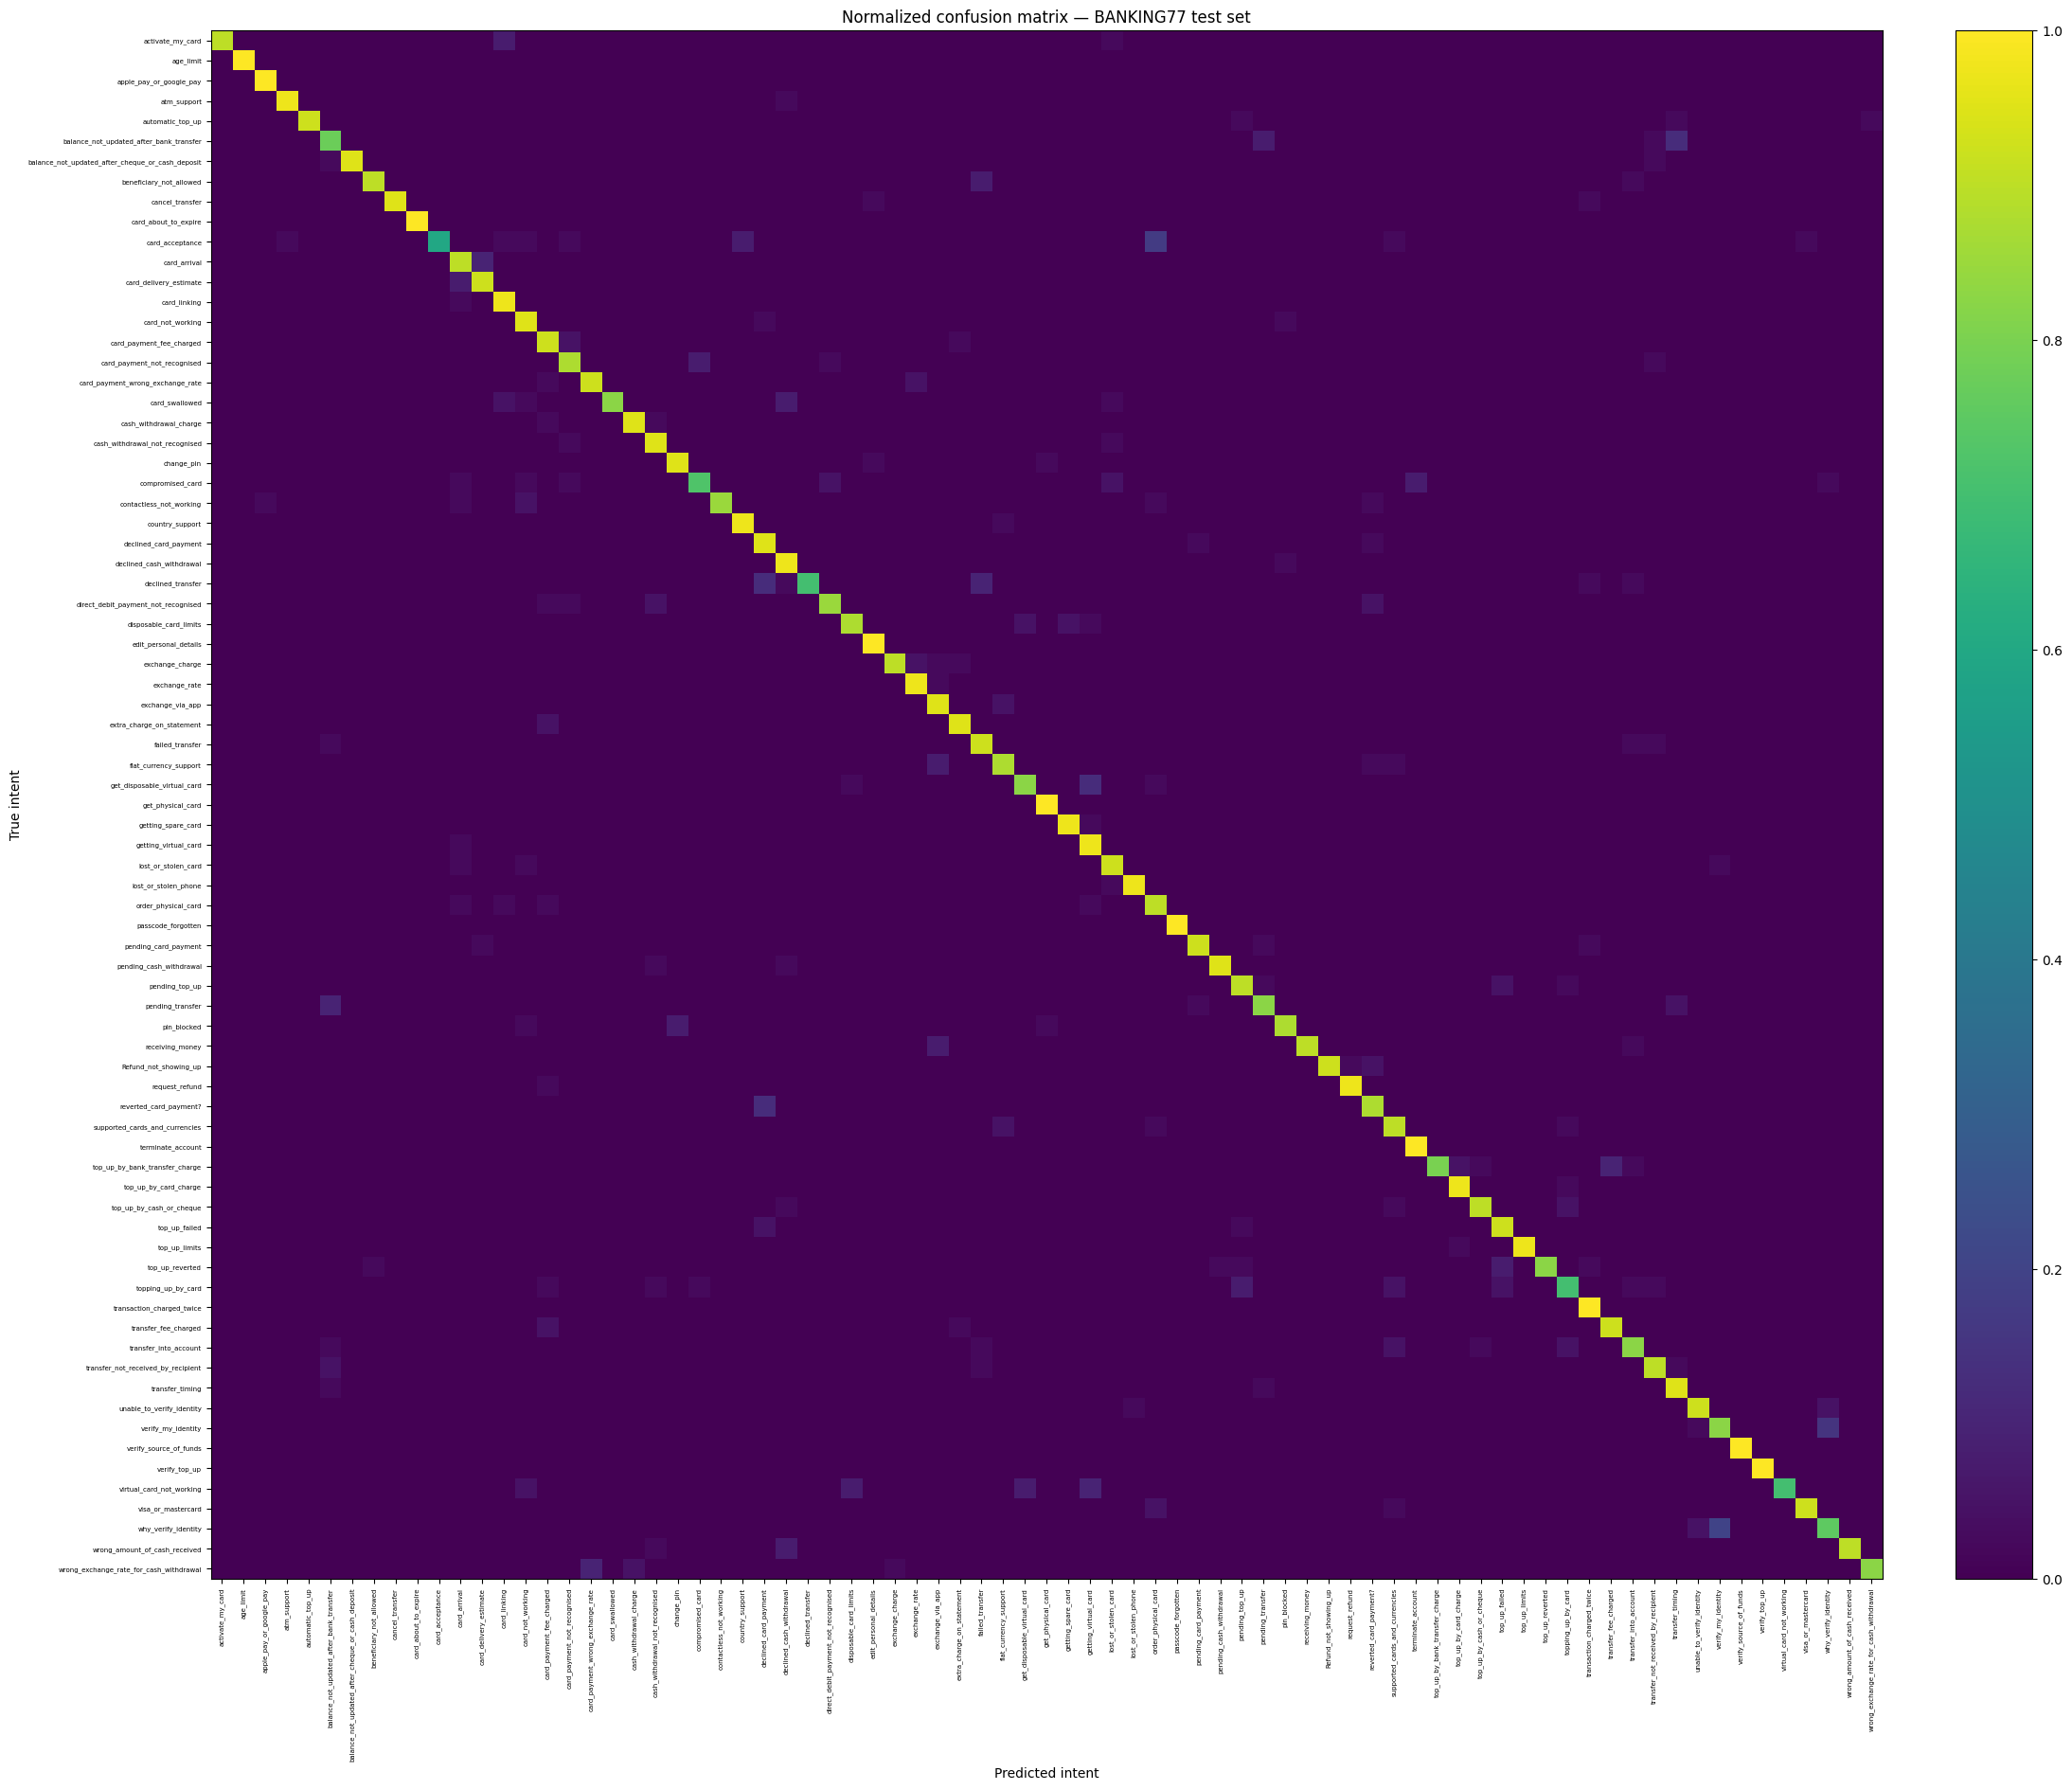

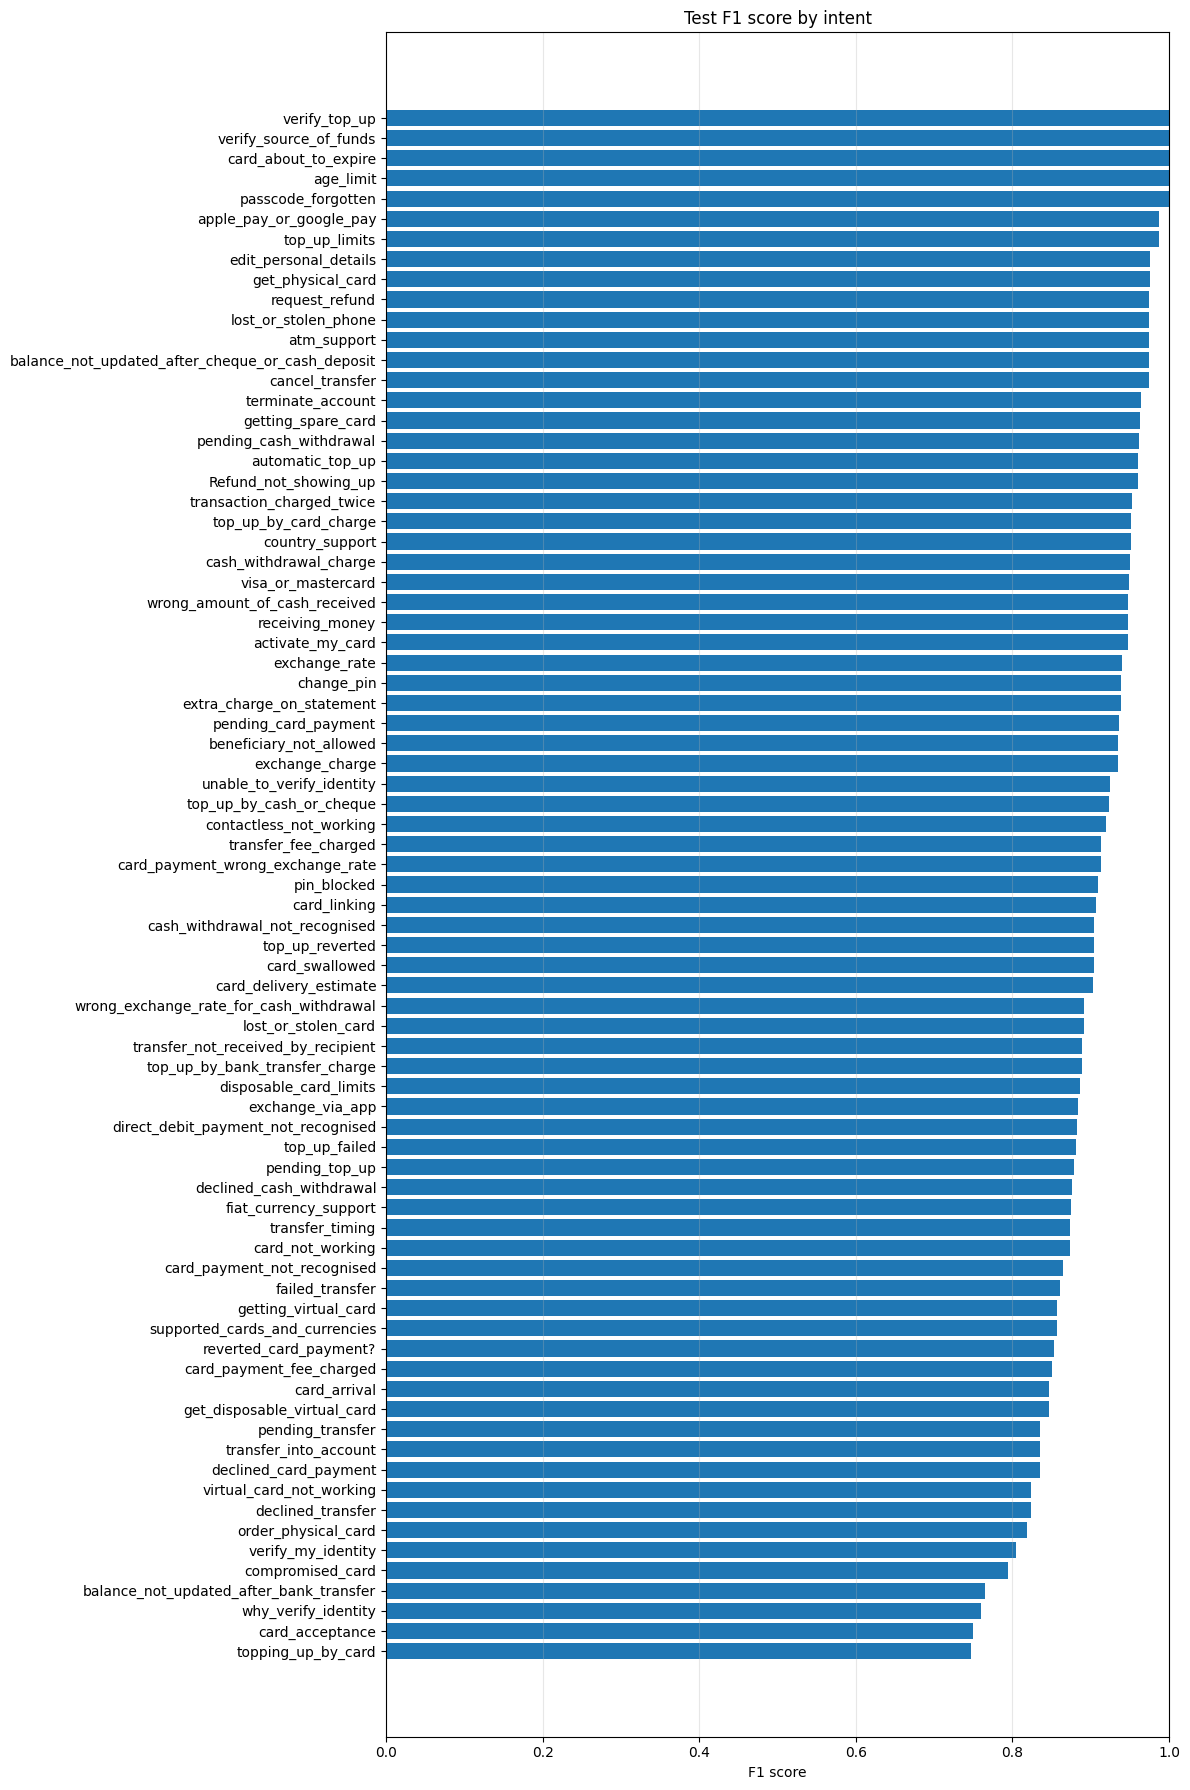

Plots saved to: /content/drive/MyDrive/ComPlaintAI-Bank/training_runs/bert_banking77_20261017_123648


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if "loss" in history_df.columns:
    curve = history_df.dropna(subset=["loss"])
    axes[0].plot(curve["step"] if "step" in curve else np.arange(len(curve)), curve["loss"], label="Training loss")
if "eval_loss" in history_df.columns:
    curve = history_df.dropna(subset=["eval_loss"])
    axes[0].plot(curve["epoch"] if "epoch" in curve else np.arange(len(curve)), curve["eval_loss"], marker="o", label="Validation loss")
axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Step / epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

if "eval_macro_f1" in history_df.columns:
    curve = history_df.dropna(subset=["eval_macro_f1"])
    axes[1].plot(curve["epoch"] if "epoch" in curve else np.arange(len(curve)), curve["eval_macro_f1"], marker="o", label="Validation macro-F1")
if "eval_accuracy" in history_df.columns:
    curve = history_df.dropna(subset=["eval_accuracy"])
    axes[1].plot(curve["epoch"] if "epoch" in curve else np.arange(len(curve)), curve["eval_accuracy"], marker="o", label="Validation accuracy")
axes[1].set_title("Validation metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(22, 19))
im = ax.imshow(cm_norm, interpolation="nearest", aspect="auto")
ax.set_title("Normalized confusion matrix — BANKING77 test set")
ax.set_xlabel("Predicted intent")
ax.set_ylabel("True intent")
ax.set_xticks(np.arange(num_labels))
ax.set_yticks(np.arange(num_labels))
ax.set_xticklabels(label_names, rotation=90, fontsize=5)
ax.set_yticklabels(label_names, fontsize=5)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(RUN_DIR / "confusion_matrix_normalized.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

per_class = report_df.loc[label_names, ["precision", "recall", "f1-score", "support"]].sort_values("f1-score")
fig, ax = plt.subplots(figsize=(12, 18))
ax.barh(per_class.index, per_class["f1-score"])
ax.set_title("Test F1 score by intent")
ax.set_xlabel("F1 score")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(RUN_DIR / "per_intent_f1.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Plots saved to:", RUN_DIR)

## 12. Save the best model and metadata to Drive

The Trainer has loaded the checkpoint selected by validation macro-F1. This cell saves the model weights, model configuration, tokenizer and intent mapping to a stable folder for later inference.

In [13]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

label_mapping = {
    "model_name": MODEL_NAME,
    "num_labels": int(num_labels),
    "id_to_label": {str(k): v for k, v in id_to_label.items()},
    "label_to_id": label_to_id,
}
(MODEL_DIR / "label_mapping.json").write_text(
    json.dumps(label_mapping, ensure_ascii=False, indent=2), encoding="utf-8"
)

config = {
    "base_model": MODEL_NAME, "dataset": "PolyAI/banking77",
    "train_examples_before_validation_split": int(len(train_df)),
    "train_examples_used": int(len(train_part_df)),
    "validation_examples": int(len(val_df)), "official_test_examples": int(len(test_df)),
    "num_labels": int(num_labels), "label_names": label_names,
    "max_length": int(MAX_LENGTH), "num_train_epochs_requested": int(NUM_EPOCHS),
    "learning_rate": float(LEARNING_RATE), "train_batch_size": int(TRAIN_BATCH_SIZE),
    "eval_batch_size": int(EVAL_BATCH_SIZE), "validation_size": float(VALIDATION_SIZE),
    "seed": int(SEED), "gpu_available": bool(torch.cuda.is_available()),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "best_validation_macro_f1": float(trainer.state.best_metric) if trainer.state.best_metric is not None else None,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "training_wall_time_seconds": float(training_wall_time_seconds),
    "created_utc": datetime.now(timezone.utc).isoformat(),
}
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

bundle = {
    "test_metrics": test_metrics,
    "train_metrics": {k: float(v) for k, v in train_metrics.items()
                      if isinstance(v, (int, float, np.integer, np.floating))},
    "best_validation_macro_f1": config["best_validation_macro_f1"],
    "training_config": config,
}
(RUN_DIR / "metrics_and_config.json").write_text(
    json.dumps(bundle, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)

readme_content = (
    "# ComPlaintAI-Bank BANKING77 BERT model\n\n"
    f"- Base model: {MODEL_NAME}\n"
    "- Task: 77-class BANKING77 intent classification\n"
    "- Model selection metric: validation macro-F1\n"
    f"- Best validation macro-F1: {trainer.state.best_metric}\n"
    f"- Maximum sequence length: {MAX_LENGTH}\n"
    "- Label mapping: `label_mapping.json`\n"
    "- Training metadata: `model_metadata.json`\n"
    "- Detailed reports: matching timestamped folder under `training_runs/`\n\n"
    "Load with `AutoTokenizer.from_pretrained(model_dir)` and "
    "`AutoModelForSequenceClassification.from_pretrained(model_dir)`. "
    "Intent prediction is not proof that a complaint allegation is true.\n"
)
(MODEL_DIR / "README.md").write_text(readme_content, encoding="utf-8")

print("Best model saved to:", MODEL_DIR)
print("Reports saved to:", RUN_DIR)
for p in sorted(MODEL_DIR.iterdir()):
    if p.is_file():
        print(f"  {p.name:34s} {p.stat().st_size / (1024**2):8.2f} MB")

Best model saved to: /content/drive/MyDrive/ComPlaintAI-Bank/models/bert_banking77_model
Reports saved to: /content/drive/MyDrive/ComPlaintAI-Bank/training_runs/bert_banking77_20261017_123648
  README.md                              0.00 MB
  config.json                            0.01 MB
  label_mapping.json                     0.00 MB
  model.safetensors                    417.89 MB
  model_metadata.json                    0.00 MB
  special_tokens_map.json                0.00 MB
  tokenizer.json                         0.68 MB
  tokenizer_config.json                  0.00 MB
  training_args.bin                      0.01 MB
  vocab.txt                              0.22 MB


## 13. Reload test — verify the saved model works

In [14]:
saved_tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR), use_fast=True)
saved_model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_DIR))
saved_model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
saved_model.to(device)

smoke_texts = [
    "I do not recognize this card payment.",
    "My bank transfer has not arrived yet.",
    "How can I activate my card?",
]
inputs = saved_tokenizer(smoke_texts, return_tensors="pt", truncation=True,
                         max_length=MAX_LENGTH, padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    logits = saved_model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)
    confs, ids = torch.max(probs, dim=-1)

for text, idx, confidence in zip(smoke_texts, ids.cpu().tolist(), confs.cpu().tolist()):
    print("Text:", text)
    print("Predicted intent:", id_to_label[int(idx)])
    print(f"Top-class model probability: {confidence:.4f}")
    print("-" * 60)

del saved_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Saved-model reload test passed.")

Text: I do not recognize this card payment.
Predicted intent: card_payment_not_recognised
Top-class model probability: 0.8229
------------------------------------------------------------
Text: My bank transfer has not arrived yet.
Predicted intent: balance_not_updated_after_bank_transfer
Top-class model probability: 0.6296
------------------------------------------------------------
Text: How can I activate my card?
Predicted intent: activate_my_card
Top-class model probability: 0.8918
------------------------------------------------------------
Saved-model reload test passed.


## 14. Create a ZIP backup and validate saved artifacts

The folder is best for loading the model in Python; the ZIP is a portable copy for transfer or upload.

In [15]:
zip_path = MODEL_DIR.parent / "bert_banking77_model.zip"
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1) as zf:
    for file_path in MODEL_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=str(file_path.relative_to(MODEL_DIR.parent)))

required = ["config.json", "label_mapping.json", "model_metadata.json", "README.md"]
missing = [name for name in required if not (MODEL_DIR / name).exists()]
if not (MODEL_DIR / "model.safetensors").exists() and not (MODEL_DIR / "pytorch_model.bin").exists():
    missing.append("model.safetensors or pytorch_model.bin")
if not any(MODEL_DIR.glob("tokenizer*")) and not (MODEL_DIR / "vocab.txt").exists():
    missing.append("tokenizer files")
if missing:
    raise FileNotFoundError(f"Model artifact validation failed: {missing}")

print("ARTIFACT VALIDATION PASSED")
print("Model folder:", MODEL_DIR)
print("Model ZIP:", zip_path, f"({zip_path.stat().st_size / (1024**2):.2f} MB)")
print("Reports:", RUN_DIR)
print("\nReport files:")
for p in sorted(RUN_DIR.iterdir()):
    if p.is_file():
        print(f"  {p.name:38s} {p.stat().st_size / 1024:10.1f} KB")

ARTIFACT VALIDATION PASSED
Model folder: /content/drive/MyDrive/ComPlaintAI-Bank/models/bert_banking77_model
Model ZIP: /content/drive/MyDrive/ComPlaintAI-Bank/models/bert_banking77_model.zip (388.61 MB)
Reports: /content/drive/MyDrive/ComPlaintAI-Bank/training_runs/bert_banking77_20261017_123648

Report files:
  classification_report.csv                     4.9 KB
  confusion_matrix_counts.csv                  14.9 KB
  confusion_matrix_normalized.csv              26.8 KB
  confusion_matrix_normalized.png             532.8 KB
  dataset_split_summary.csv                     2.6 KB
  metrics_and_config.json                       4.0 KB
  per_intent_f1.png                           454.1 KB
  test_metrics_summary.csv                      0.5 KB
  test_predictions.csv                        568.7 KB
  training_curves.png                         122.7 KB
  training_history.csv                          3.2 KB


## 15. Completion checklist

The final cell should print **`ARTIFACT VALIDATION PASSED`**.

Expected Drive locations:
- Model folder: `MyDrive/ComPlaintAI-Bank/models/bert_banking77_model/`
- Portable ZIP: `MyDrive/ComPlaintAI-Bank/models/bert_banking77_model.zip`
- Metrics, predictions, per-class report and plots: `MyDrive/ComPlaintAI-Bank/training_runs/bert_banking77_<timestamp>/`

Metrics are a comprehensive set of standard evaluation measures, not literally every possible metric. Macro-F1 and per-intent metrics are particularly useful for evaluating a 77-class intent classifier. If training fails, copy the first full traceback before rerunning.